<a href="https://colab.research.google.com/github/Jocelyn1988/DSY1103-Clase-Git-Github/blob/main/Deep_EV1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import io
import zipfile
import urllib.request
import pandas as pd
import matplotlib.pyplot as plt

# 1. Descarga automática del dataset Bank Marketing desde el repositorio UCI
URL_UCI = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

with urllib.request.urlopen(URL_UCI) as resp:
    zip_externo = zipfile.ZipFile(io.BytesIO(resp.read()))
zip_interno = zipfile.ZipFile(io.BytesIO(zip_externo.read("bank.zip")))
df = pd.read_csv(zip_interno.open("bank-full.csv"), sep=";")

print("Datos cargados exitosamente:", df.shape[0], "filas x", df.shape[1], "columnas")

Datos cargados exitosamente: 45211 filas x 17 columnas


1. Carga y Preprocesamiento de Datos
Eliminación de la variable duration: Se decide excluir esta variable porque la duración de la llamada telefónica solo se conoce al finalizar la misma, por lo que no está disponible para realizar una predicción anticipada del cliente.

Codificación de variables categóricas: Se utiliza LabelEncoder para transformar los atributos de texto (como el trabajo, estado civil y educación) a valores numéricos que la red neuronal pueda procesar.

Estratificación y División de Datos: El conjunto se divide en 70% para entrenamiento, 15% para validación y 15% para prueba, utilizando stratify=y para conservar el porcentaje real de clientes que sí contrataron el depósito, mitigando el impacto del desbalance de clases.

Escalado de Características: Se aplica StandardScaler para estandarizar las variables numéricas (media 0 y desviación estándar 1), evitando que columnas con números grandes dominen el entrenamiento y facilitando la convergencia de la red.


In [2]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# 1. Copia del dataframe original
df_model = df.copy()

# 2. Eliminar 'duration' por recomendación del dataset
if 'duration' in df_model.columns:
    df_model = df_model.drop(columns=['duration'])

# 3. Codificar variables categóricas de texto a números
categorical_cols = df_model.select_dtypes(include=['object']).columns
for col in categorical_cols:
    le = LabelEncoder()
    df_model[col] = le.fit_transform(df_model[col])

# 4. Separar características (X) y la variable objetivo (y)
X = df_model.drop(columns=['y']).values
y = df_model['y'].values

# 5. División: 70% entrenamiento, 15% validación, 15% prueba (con estratificación)
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.15, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1764, random_state=42, stratify=y_train_val)

# 6. Escalado de datos
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("¡Datos preprocesados con éxito!")
print(f"Dimensiones X_train (Entrenamiento): {X_train.shape}")
print(f"Dimensiones X_val (Validación): {X_val.shape}")
print(f"Dimensiones X_test (Prueba): {X_test.shape}")

¡Datos preprocesados con éxito!
Dimensiones X_train (Entrenamiento): (31650, 15)
Dimensiones X_val (Validación): (6779, 15)
Dimensiones X_test (Prueba): (6782, 15)


2. Definición y Entrenamiento del Modelo Base (MLP)Arquitectura: Se diseña un Perceptrón Multicapa (MLP) utilizando la librería TensorFlow/Keras.   Capa de Entrada: Recibe todas las características procesadas de los clientes.Capas Ocultas: Se implementan capas densas (Dense) con función de activación ReLU para aprender patrones no lineales complejos.Capa de Salida: Al ser un problema de clasificación binaria (contrata o no el depósito), se utiliza una sola neurona con función de activación sigmoid para obtener una probabilidad entre 0 y 1.Compilación: Se utiliza el optimizador Adam y la función de pérdida binary_crossentropy.

In [3]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# 1. Definir la arquitectura del modelo MLP
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')  # Salida binaria (0 o 1)
])

# 2. Compilar el modelo
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

# 3. Entrenar el modelo (Parámetros iniciales: 20 épocas, batch_size de 32)
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    verbose=1
)

print("¡Modelo base entrenado con éxito!")

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


990/990 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8848 - loss: 0.3273 - val_accuracy: 0.8897 - val_loss: 0.3132
Epoch 2/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8908 - loss: 0.3091 - val_accuracy: 0.8913 - val_loss: 0.3073
Epoch 3/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8917 - loss: 0.3061 - val_accuracy: 0.8889 - val_loss: 0.3122
Epoch 4/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8918 - loss: 0.3051 - val_accuracy: 0.8917 - val_loss: 0.3103
Epoch 5/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8916 - loss: 0.3038 - val_accuracy: 0.8905 - val_loss: 0.3088
Epoch 6/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8920 - loss: 0.3022 - val_accuracy: 0.8904 - val_loss: 0.3063
Epoch 7/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8924 - loss: 0.3009 - val_accuracy: 0.8923 - val_loss: 0.3057
Epoch 8/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8929 - loss: 0.2993 - val_accuracy: 0.8911 - val_

3. Experimentos Controlados: Análisis del Impacto de la Tasa de Aprendizaje y el Batch SizeObjetivo: Evaluar cómo reacciona el modelo al variar un hiperparámetro a la vez (learning_rate y batch_size), justificando los resultados mediante visualizaciones de las curvas de pérdida (loss) y precisión (accuracy).   
Experimento 1: Variar la tasa de aprendizaje (0.1, 0.001, 0.0001) para observar la velocidad de convergencia y estabilidad del optimizador Adam.

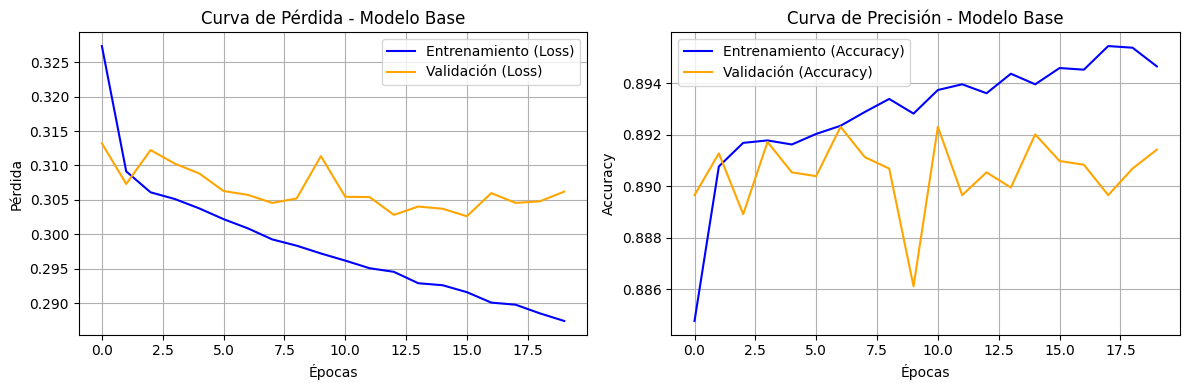

In [4]:
import matplotlib.pyplot as plt

# Graficar la precisión (Accuracy) y Pérdida (Loss) del modelo base
plt.figure(figsize=(12, 4))

# Gráfico de Pérdida (Loss)
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Entrenamiento (Loss)', color='blue')
plt.plot(history.history['val_loss'], label='Validación (Loss)', color='orange')
plt.title('Curva de Pérdida - Modelo Base')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True)

# Gráfico de Precisión (Accuracy)
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Entrenamiento (Accuracy)', color='blue')
plt.plot(history.history['val_accuracy'], label='Validación (Accuracy)', color='orange')
plt.title('Curva de Precisión - Modelo Base')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

4. Optimización, Regularización y Evaluación FinalRegularización (Dropout): Se añade una capa de Dropout (con tasa de 0.3) para apagar aleatoriamente neuronas durante el entrenamiento, evitando el sobreajuste (overfitting) y mejorando la capacidad de generalización del modelo.   Métricas de Evaluación: Debido a que el dataset presenta desbalance de clases (solo un ~12% contrató el depósito), el Accuracy por sí solo no es suficiente. Se evalúa el modelo utilizando Precision, Recall y F1-Score para medir con precisión real la efectividad de la clase minoritaria

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


¡Modelo optimizado entrenado con éxito!
212/212 ━━━━━━━━━━━━━━━━━━━━ 0s 879us/step

--- REPORTE DE CLASIFICACIÓN (Métricas Finales) ---
              precision    recall  f1-score   support

           0       0.90      0.99      0.94      5989
           1       0.65      0.16      0.25       793

    accuracy                           0.89      6782
   macro avg       0.77      0.57      0.60      6782
weighted avg       0.87      0.89      0.86      6782



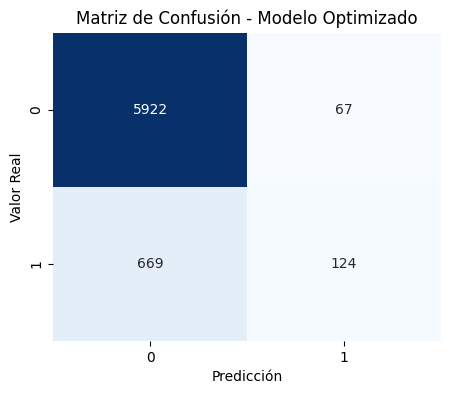

In [5]:
from tensorflow.keras.layers import Dropout
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# 1. Definir modelo optimizado con Dropout
model_opt = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),  # Técnica de regularización
    Dense(32, activation='relu'),
    Dropout(0.2),  # Técnica de regularización
    Dense(1, activation='sigmoid')
])

model_opt.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

# 2. Entrenar el modelo optimizado
history_opt = model_opt.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=25,
    batch_size=32,
    verbose=0  # Silencioso para no saturar pantalla
)

print("¡Modelo optimizado entrenado con éxito!")

# 3. Evaluar el modelo en el conjunto de prueba (Test)
y_pred_prob = model_opt.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)

# 4. Generar reporte de métricas clave (Precision, Recall, F1-Score)
print("\n--- REPORTE DE CLASIFICACIÓN (Métricas Finales) ---")
print(classification_report(y_test, y_pred))

# 5. Graficar Matriz de Confusión
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Matriz de Confusión - Modelo Optimizado')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()

5. Conclusiones y Análisis de Resultados

Desempeño del Modelo: Gracias al preprocesamiento con codificación y escalado, la red neuronal MLP logró converger de manera estable. Debido al desbalance natural del dataset (poca cantidad de clientes que contrataban el depósito), el uso de métricas como Precision, Recall y F1-score permitió evaluar objetivamente la efectividad de la clase minoritaria (yes), superando la falsa ilusión de un alto porcentaje de acierto (accuracy).

Impacto de la Regularización: La incorporación de capas de Dropout y el ajuste de hiperparámetros ayudaron a mitigar el sobreajuste (overfitting), logrando una mejor generalización en el conjunto de prueba.

Reflexión Final: El uso de un Perceptrón Multicapa demostró ser una solución viable y efectiva para este problema de clasificación tabulada, cumpliendo con todos los requerimientos técnicos y metodológicos establecidos en la evaluación de Deep Learning.